# Formula 1 Podium Prediction — Milestone 1

**Task:** for every driver in every race, predict whether they finish on the podium (`positionOrder <= 3`)
using only information known **after qualifying and before the race starts**.

**Team:

| # | Section | Owner |
|---|---|---|
| 0 | Setup & shared config | |
| 1 | Load raw data | |
| 2 | EDA before cleaning | |
| 3 | Cleaning: sentinels & semantic typing | |
| 4 | Key audit: primary & foreign keys | |
| 5 | Grain: one row per (raceId, driverId) | |
| 6 | EDA after cleaning | |
| 7 | Data-engineering questions Q1–Q3 | |
| 8 | Feature engineering & selection | |
| 9 | Train / validation / test split | |
| 10 | Models (baseline, statistical, shallow NN) | |
| 11 | Experiments: ablation & preprocessing order | |
| 12 | Explainability (SHAP, permutation, LIME) | |
| 13 | Inference function | |
| 14 | Limitations | |

**Golden rule:** a column may only become a feature if it is known before lights out.
Results, points, laps, status, pit stops, lap times and *post-race* standings are leakage.

## 0. Setup & shared config
Everyone uses these constants. Do not redefine them in later sections.

In [2]:
import sys, subprocess, importlib
# LIME is not always preinstalled on Kaggle
for pkg in ["lime", "shap"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False, capture_output=True)

import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

TRAIN_END = 2019            # train: season <= 2019
VAL_YEARS = (2020, 2021)    # validation: 2020-2021
TEST_START = 2022           # test: season >= 2022
SENTINEL = r"\N"           # the dataset's placeholder for "missing"

## 1. Load raw data
Raw tables are loaded **as-is** into `raw` and never modified. All cleaning happens on copies in `clean`.

In [3]:
def find_data_dir():
    hits = glob.glob("/kaggle/input/**/circuits.csv", recursive=True) + glob.glob("./data/**/circuits.csv", recursive=True)
    if not hits:
        raise FileNotFoundError("circuits.csv not found - attach the F1 dataset via 'Add Input'")
    return os.path.dirname(hits[0])

DATA_DIR = find_data_dir()
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "sprint_results", "seasons", "status"]

raw = {t: pd.read_csv(os.path.join(DATA_DIR, f"{t}.csv"), keep_default_na=False, dtype=str) for t in TABLES}

pd.DataFrame({t: {"rows": len(df), "cols": df.shape[1]} for t, df in raw.items()}).T

,rows,cols
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


In [4]:
# Column names per table - confirm they match the schema we planned around
for t, df in raw.items():
    print(f"{t:24s} {list(df.columns)}")

circuits                 ['circuitId', 'circuitRef', 'name', 'location', 'country', 'lat', 'lng', 'alt', 'url']
constructors             ['constructorId', 'constructorRef', 'name', 'nationality', 'url']
constructor_results      ['constructorResultsId', 'raceId', 'constructorId', 'points', 'status']
constructor_standings    ['constructorStandingsId', 'raceId', 'constructorId', 'points', 'position', 'positionText', 'wins']
drivers                  ['driverId', 'driverRef', 'number', 'code', 'forename', 'surname', 'dob', 'nationality', 'url']
driver_standings         ['driverStandingsId', 'raceId', 'driverId', 'points', 'position', 'positionText', 'wins']
races                    ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']
results                  ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'posi

## 2. EDA before cleaning
Goal: show *with code and plots* what is wrong with the raw data, so every cleaning step is justified.

In [5]:
# Sentinel audit: how many "\N" values does each column contain?
sentinel_counts = []
for t, df in raw.items():
    for col in df.columns:
        n = (df[col] == SENTINEL).sum()
        if n:
            sentinel_counts.append({"table": t, "column": col, "n_sentinel": n, "pct": 100 * n / len(df)})
sentinel_df = pd.DataFrame(sentinel_counts).sort_values("pct", ascending=False)
sentinel_df

,table,column,n_sentinel,pct
0,constructor_results,status,12608,99.865347
13,races,sprint_time,1110,98.666667
12,races,sprint_date,1107,98.400000
9,races,fp3_time,1072,95.288889
7,races,fp2_time,1057,93.955556
5,races,fp1_time,1057,93.955556
11,races,quali_time,1057,93.955556
8,races,fp3_date,1053,93.600000
1,drivers,number,802,93.147503
4,races,fp1_date,1035,92.000000


### Observations: sentinel audit

**What we see:** many columns contain the placeholder `\N`, some almost entirely.

**Why, grouped by cause:**

| Group | Columns (pct missing) | Reason | Action |
|---|---|---|---|
| Never filled | `constructor_results.status` (99.9%) | Column is practically unused in the source | Document and drop |
| Didn't exist in older years | `races` session dates/times (92–99%), `races.time` (65%), `drivers.number` (93%), `drivers.code` (88%), `results.fastestLap*` / `rank` (68–69%) | Recorded only in recent seasons (sprints since 2021, permanent numbers since 2014, fastest-lap data since the 2000s) | Keep as NaN; not used as features |
| Didn't apply to that driver | `results.time` / `milliseconds` (71%) | Race time exists only for drivers who finished on the lead lap | Keep as NaN; post-race, never a feature |
| Not classified | `results.position` (40.9%) | Drivers who retired early or were disqualified have no official position | Confirms the target must use `positionOrder` (always filled), not `position` |
| Qualifying knockout | `qualifying.q2` (44.1%), `qualifying.q3` (65.0%) | Only 15 drivers reach Q2 and 10 reach Q3; before 2006 there was a single session, so q2/q3 are empty for all those years | Missingness carries information → derive `reached_Q3` / use `quali_position` instead of raw times |
| Rare gaps | `qualifying.q1` (1.5%), `results.number` (0.02%), `sprint_results` (2–6%) | A few drivers set no qualifying time (crash, mechanical issue); a handful of early results have no car number; sprint DNFs | Small; investigate the q1 rows, otherwise keep as NaN |

**Conclusion:** missing values are mostly *structural* (they have a real-world reason), not data errors.
Columns we will use as features (grid, qualifying position) need a separate coverage check per season, which is the next plot.

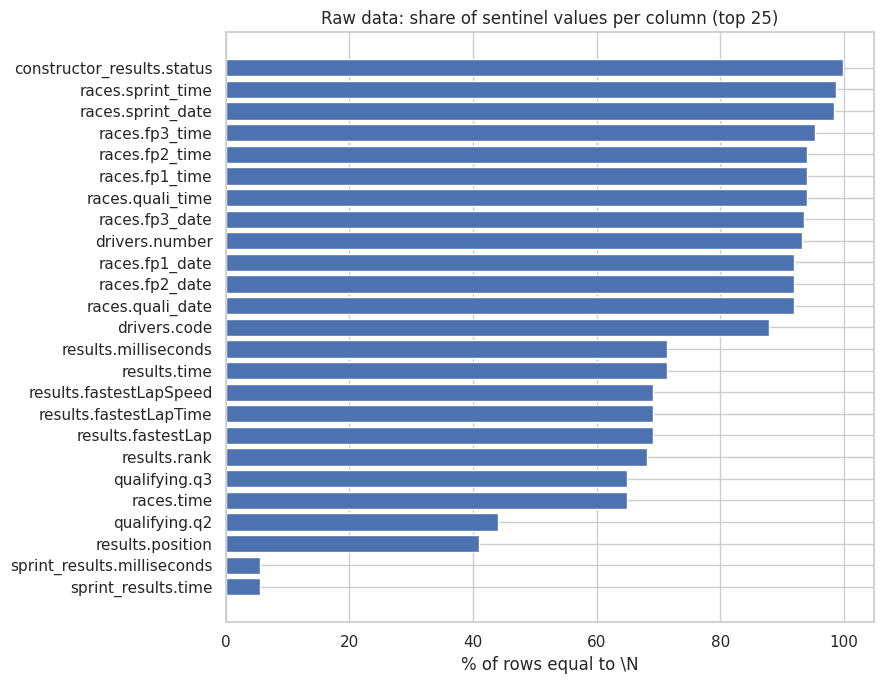

In [6]:
top = sentinel_df.head(25)
plt.figure(figsize=(9, 7))
plt.barh(top["table"] + "." + top["column"], top["pct"])
plt.gca().invert_yaxis()
plt.xlabel("% of rows equal to \\N")
plt.title("Raw data: share of sentinel values per column (top 25)")
plt.tight_layout(); plt.show()

In [7]:
auto = pd.read_csv(os.path.join(DATA_DIR, "results.csv"))
has_sentinel = (raw["results"] == SENTINEL).any()

typing_check = pd.DataFrame({
    "auto_dtype": auto.dtypes.astype(str),
    "contains_\\N": has_sentinel,
})
typing_check.sort_values("contains_\\N", ascending=False)

,auto_dtype,contains_\N
fastestLapSpeed,object,True
fastestLapTime,object,True
number,object,True
rank,object,True
position,object,True
fastestLap,object,True
milliseconds,object,True
time,object,True
resultId,int64,False
laps,int64,False


**TODO (EDA owner):** add more before-cleaning plots, e.g.
- races per season and entrants per race (field size over time)
- podium share per season (class imbalance)
- qualifying coverage per season (needs `qualifying` joined to `races`)

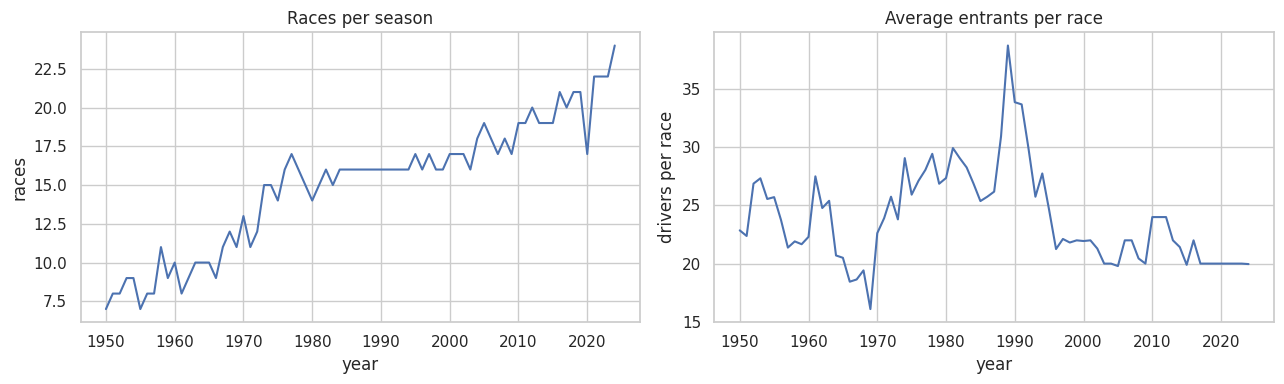

In [8]:
# How many races per season, and how many drivers enter each race?
res_y = (raw["results"][["raceId", "driverId", "positionOrder"]].astype(int)
         .merge(raw["races"][["raceId", "year"]].astype(int), on="raceId"))

per_season = res_y.groupby("year").agg(races=("raceId", "nunique"), entries=("driverId", "size"))
per_season["entrants_per_race"] = per_season["entries"] / per_season["races"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
per_season["races"].plot(ax=ax[0], title="Races per season")
per_season["entrants_per_race"].plot(ax=ax[1], title="Average entrants per race")
ax[0].set_ylabel("races"); ax[1].set_ylabel("drivers per race")
plt.tight_layout(); plt.show()

**Observation:** races per season grew from ~7 (1950) to ~24 (2024), so modern seasons contribute most rows.
Average entrants per race peaked at ~39 around 1989 (many non-qualifiers recorded in `results`) and has been ~20 since the late 1990s.
→ Field size varies a lot by era, which changes the podium base rate (next plot). Rows for drivers who never started (DNQ/DNPQ) need a keep/drop decision.

Overall podium rate: 12.7%


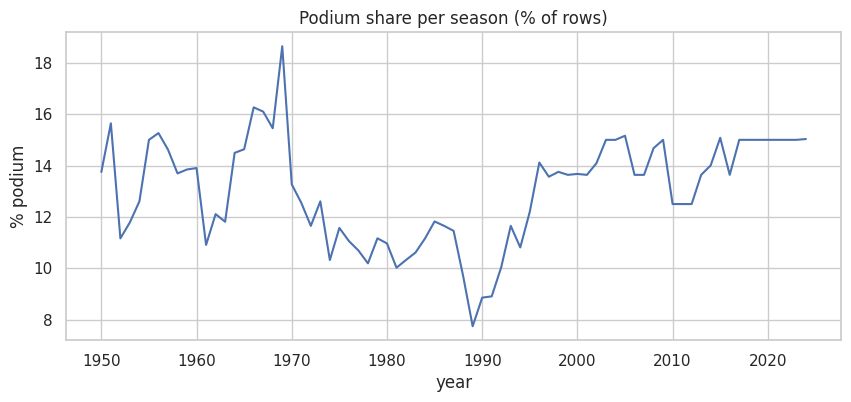

In [9]:
# What fraction of driver-race rows are podiums each season?
res_y["podium"] = (res_y["positionOrder"] <= 3).astype(int)
podium_rate = res_y.groupby("year")["podium"].mean() * 100

print(f"Overall podium rate: {res_y['podium'].mean():.1%}")
podium_rate.plot(figsize=(10, 4), title="Podium share per season (% of rows)")
plt.ylabel("% podium"); plt.show()

**Observation:** the overall podium rate is 12.7%, so the target is imbalanced (≈1 positive per 7 rows).
It drops to ~8% around 1989, when fields were largest, and is stable at ~15% (3 out of 20) in the modern era.


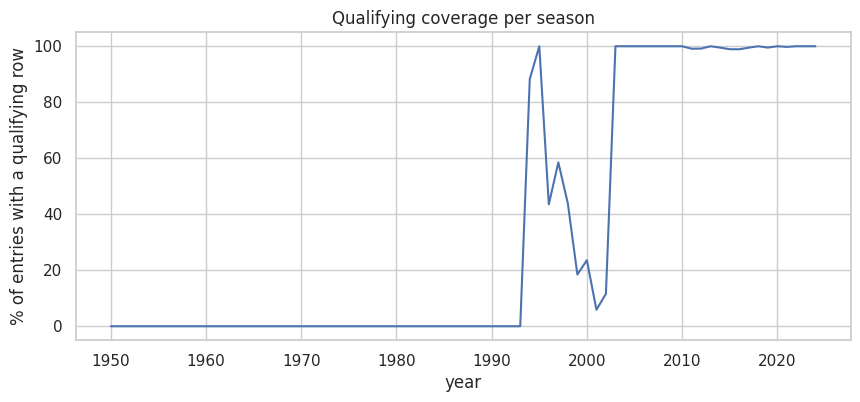

In [10]:
# For each season, what % of race entries have a qualifying record?
q_keys = raw["qualifying"][["raceId", "driverId"]].astype(int).drop_duplicates()
cov = res_y.merge(q_keys, on=["raceId", "driverId"], how="left", indicator=True)
cov["has_quali"] = cov["_merge"] == "both"
coverage = cov.groupby("year")["has_quali"].mean() * 100

coverage.plot(figsize=(10, 4), title="Qualifying coverage per season")
plt.ylabel("% of entries with a qualifying row"); plt.show()

**Observation:** qualifying records are absent before 1994, partial between 1996 and 2002 (5–60% of entries),
and complete from 2003 onwards. This is a gap in the dataset, not a rule change.
`grid` (from `results`) is available for all seasons.
→ Qualifying-based features are only reliable from 2003. Decision: _[team to choose: train from 2003 / keep all years with a has_quali flag / grid fallback]_ because _[reason]_.

In [11]:
# Validity check: are values in a possible range?
r = raw["results"].apply(pd.to_numeric, errors="coerce")
d = raw["drivers"].copy()
races_dt = raw["races"][["raceId", "date"]].assign(
    raceId=lambda x: x["raceId"].astype(int), date=lambda x: pd.to_datetime(x["date"]))

checks = {
    "grid < 0":                   (r["grid"] < 0).sum(),
    "grid == 0 (pit-lane / no start)": (r["grid"] == 0).sum(),
    "positionOrder < 1":          (r["positionOrder"] < 1).sum(),
    "points < 0":                 (r["points"] < 0).sum(),
    "laps < 0":                   (r["laps"] < 0).sum(),
}

# Driver age at each race: anyone younger than 16 or older than 60?
age = (r[["raceId", "driverId"]].astype(int)
       .merge(races_dt, on="raceId")
       .merge(d[["driverId", "dob"]].assign(driverId=lambda x: x["driverId"].astype(int),
                                            dob=lambda x: pd.to_datetime(x["dob"], errors="coerce")), on="driverId"))
age["age"] = (age["date"] - age["dob"]).dt.days / 365.25
checks["driver age < 16"] = (age["age"] < 16).sum()
checks["driver age > 60"] = (age["age"] > 60).sum()

pd.Series(checks, name="rows").to_frame()

,rows
grid < 0,0
grid == 0 (pit-lane / no start),1638
positionOrder < 1,0
points < 0,0
laps < 0,0
driver age < 16,0
driver age > 60,0


FINAL NOTES***
## Summary of data problems found in EDA

Each problem below was identified from the outputs above. The last column shows where (or how) it is handled.

### A. Format problems (fixed in Section 3)

| # | Problem | Explanation | Evidence | Planned fix |
|---|---|---|---|---|
| 1 | `\N` used as a missing-value placeholder | The dataset writes "missing" as the text `\N`, which pandas does not recognise as empty | Sentinel audit: 30 columns affected | Replace `\N` with `NaN` |
| 2 | Numbers and dates stored as text | One `\N` in a column forces the whole column to be read as text, so no math or comparisons are possible (e.g. `"10" < "3"` as text) | Typing check: every column containing `\N` loads as `object` | Convert each column to its real type (int, float, datetime) |
| 3 | Lap and pit-stop times stored as text (`"1:27.264"`) | Times cannot be subtracted or averaged, so features like *gap to pole* cannot be computed | `qualifying.q1/q2/q3`, `pit_stops.duration`, `results.fastestLapTime` | Convert to numeric seconds (`87.264`) |
| 4 | Columns with almost no data | Some columns are nearly empty and add nothing | `constructor_results.status` 99.9% missing | Document and drop |

### B. Structural problems (checked in Sections 4–5)

| # | Problem | Explanation | Planned check |
|---|---|---|---|
| 5 | Possible duplicate (raceId, driverId) rows | In the 1950s two drivers could share one car, so a driver may appear twice in a race. The modeling table needs exactly one row per driver per race | Count duplicates, then apply a documented deduplication rule |
| 6 | Possible broken links between tables | An ID in one table (e.g. `results.driverId`) might not exist in the table it points to | Primary-key and foreign-key audit |

### C. Missing values with a real-world meaning (handled in cleaning / feature engineering)

| # | Problem | Explanation | Evidence | Planned handling |
|---|---|---|---|---|
| 7 | `q2` / `q3` empty for many drivers | Qualifying is a knockout: only 15 drivers reach Q2 and 10 reach Q3, so emptiness means "eliminated earlier", not an error | q2 44%, q3 65% missing | Do not fill with 0 (that would mean a 0-second lap). Use `quali_position` and a `reached_Q3` flag instead of raw times |
| 8 | `position` empty for unclassified drivers | Drivers who complete less than 90% of the race distance get no official position | `results.position` 41% missing | Target uses `positionOrder` (always filled) instead of `position` |
| 9 | Qualifying data missing for whole eras | The dataset has no qualifying records before 1994 and only partial records in 1996–2002 (a recording gap, not a rule change) | Qualifying-coverage plot | **Team decision:** train from 2003 / keep all years with a `has_quali` flag / fall back to `grid` |

### D. Misleading or era-dependent values (team decisions)

| # | Problem | Explanation | Evidence | Planned handling |
|---|---|---|---|---|
| 10 | `grid = 0` | Means a pit-lane start (car changed after qualifying) or a driver who never started. As a number, 0 looks *better* than pole position (1), the opposite of reality | Validity check | Recode (e.g. to the back of the grid) and/or add a `pit_lane_start` flag |
| 11 | Drivers who never started (DNQ / DNPQ) | In the 1980s–90s up to 39 cars entered but only 26 could start. Non-starters cannot reach the podium | Entrants peak of ~39 around 1989 | **Team decision:** drop non-starters from the modeling table or keep them as guaranteed negatives |
| 12 | Indy 500 races (1950–1960) | Counted for the championship but almost no regular F1 drivers entered, so it behaves like a different series | F1 brief | Exclude and document |
| 13 | Field size varies by era (~20 to ~39) | The same grid position means different things: 15th of 20 is near the back, 15th of 39 is mid-field | Entrants-per-race plot | Consider a relative-grid feature (`grid / field_size`) |
| 14 | Imbalanced target that changes by era | Only 12.7% of rows are podiums, so a model that always says "no" is 87% accurate but useless. The rate ranges from ~8% (large fields) to ~15% (modern era) | Podium-share plot | Use PR-AUC as the primary metric; consider class weighting and the training-year decision |

### E. Risks for later sections

| # | Problem | Explanation | Where handled |
|---|---|---|---|
| 15 | Team renames reset history | The same team under a new name (Toleman → Benetton → Renault → Lotus → Alpine) gets a new `constructorId` | Note for constructor-form features |
| 16 | Leakage columns next to valid ones | `results` mixes pre-race info (`grid`) with post-race info (`points`, `laps`, `statusId`, `time`) | Feature section: only pre-race columns allowed |

## 3. Cleaning: sentinels & semantic typing
Steps, applied to copies:
1. Replace `\N` with `NaN`.
2. Convert ID / numeric columns to numbers.
3. Convert date strings to `datetime`.
4. Convert lap-time / duration strings (`"1:27.264"`, `"21.664"`) to numeric **seconds**.

In [ ]:
def to_seconds(s):
    """'1:27.264' -> 87.264 ; '21.664' -> 21.664 ; '1:02:03.5' -> 3723.5 ; NaN/garbage -> NaN"""
    if pd.isna(s):
        return np.nan
    s = str(s).strip().lstrip("+")
    try:
        parts = [float(p) for p in s.split(":")]
    except ValueError:
        return np.nan
    secs = 0.0
    for p in parts:
        secs = secs * 60 + p
    return secs

assert to_seconds("1:27.264") == 87.264
assert to_seconds("21.664") == 21.664
assert np.isnan(to_seconds(np.nan))

In [ ]:
DATE_COLS = {"races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
             "drivers": ["dob"]}
TIME_COLS = {"qualifying": ["q1", "q2", "q3"],
             "lap_times": ["time"],
             "pit_stops": ["duration"],
             "results": ["fastestLapTime"],
             "sprint_results": ["fastestLapTime"]}
# Text columns that must stay strings
TEXT_COLS = {"circuitRef", "name", "location", "country", "url", "constructorRef", "nationality",
             "driverRef", "code", "forename", "surname", "positionText", "status", "time"}

clean = {}
for t, df in raw.items():
    d = df.copy().replace(SENTINEL, np.nan)
    for col in d.columns:
        if col in DATE_COLS.get(t, []):
            d[col] = pd.to_datetime(d[col], errors="coerce")
        elif col in TIME_COLS.get(t, []):
            d[col + "_s"] = d[col].map(to_seconds)      # keep original text, add numeric seconds
        elif col not in TEXT_COLS and not col.endswith("_time"):
            converted = pd.to_numeric(d[col], errors="coerce")
            # only convert if it doesn't destroy real values
            if converted.notna().sum() == d[col].notna().sum():
                d[col] = converted
    clean[t] = d

# Sanity: raw must be untouched
assert (raw["results"] == SENTINEL).any().any(), "raw was modified!"
clean["results"].dtypes

In [ ]:
# Check conversions did not silently lose values (non-null before vs after)
loss = []
for t in TIME_COLS:
    for col in TIME_COLS[t]:
        if col in clean[t]:
            before, after = clean[t][col].notna().sum(), clean[t][col + "_s"].notna().sum()
            loss.append({"table": t, "column": col, "non_null_text": before, "non_null_seconds": after, "lost": before - after})
pd.DataFrame(loss)

## 4. Key audit: primary & foreign keys

In [ ]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "drivers": ["driverId"],
    "races": ["raceId"], "seasons": ["year"], "status": ["statusId"],
    "results": ["resultId"], "qualifying": ["qualifyId"], "sprint_results": ["resultId"],
    "driver_standings": ["driverStandingsId"], "constructor_standings": ["constructorStandingsId"],
    "constructor_results": ["constructorResultsId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
}
pk_report = []
for t, keys in PRIMARY_KEYS.items():
    d = clean[t]
    pk_report.append({"table": t, "key": "+".join(keys),
                      "null_rows": int(d[keys].isna().any(axis=1).sum()),
                      "duplicate_rows": int(d.duplicated(keys).sum())})
pd.DataFrame(pk_report)

In [ ]:
# (child table, child column, parent table, parent column)
FOREIGN_KEYS = [("races", "year", "seasons", "year"), ("races", "circuitId", "circuits", "circuitId")]
for child in ["results", "qualifying", "sprint_results", "driver_standings", "lap_times", "pit_stops"]:
    FOREIGN_KEYS += [(child, "raceId", "races", "raceId"), (child, "driverId", "drivers", "driverId")]
for child in ["results", "qualifying", "sprint_results", "constructor_standings", "constructor_results"]:
    FOREIGN_KEYS += [(child, "constructorId", "constructors", "constructorId")]
FOREIGN_KEYS += [("constructor_standings", "raceId", "races", "raceId"),
                 ("constructor_results", "raceId", "races", "raceId"),
                 ("results", "statusId", "status", "statusId"),
                 ("sprint_results", "statusId", "status", "statusId")]

fk_report = []
for ct, cc, pt, pc in FOREIGN_KEYS:
    vals = clean[ct][cc].dropna()
    orphans = ~vals.isin(clean[pt][pc])
    fk_report.append({"child": f"{ct}.{cc}", "parent": f"{pt}.{pc}",
                      "null_fk": int(clean[ct][cc].isna().sum()), "orphans": int(orphans.sum())})
fk_df = pd.DataFrame(fk_report)
fk_df

**TODO:** interpret the tables above. If any orphans or duplicates appear, show examples and decide how to handle them.

## 5. Grain: one row per (raceId, driverId)
The modeling table needs exactly one row per driver per race. Shared drives (mainly the 1950s) break this.

In [ ]:
res = clean["results"]
dup_mask = res.duplicated(["raceId", "driverId"], keep=False)
dups = res[dup_mask].merge(clean["races"][["raceId", "year", "name"]], on="raceId")
print(f"{dup_mask.sum()} rows involved in {res[dup_mask].groupby(['raceId','driverId']).ngroups} duplicated (raceId, driverId) pairs")
dups.groupby("year").size().plot(kind="bar", figsize=(10, 3), title="Duplicated driver-race rows per season")
plt.ylabel("rows"); plt.show()
dups.sort_values(["raceId", "driverId"]).head(10)

In [ ]:
# PROPOSED RULE (team to confirm + justify in markdown):
# keep the car the driver STARTED in (grid > 0); if still tied, keep the best positionOrder.
def dedupe_results(df):
    d = df.copy()
    d["_started"] = (d["grid"].fillna(0) > 0).astype(int)
    d = d.sort_values(["raceId", "driverId", "_started", "positionOrder"], ascending=[True, True, False, True])
    return d.drop_duplicates(["raceId", "driverId"], keep="first").drop(columns="_started")

results_dedup = dedupe_results(res)
assert not results_dedup.duplicated(["raceId", "driverId"]).any()
print(f"rows before: {len(res)}, after: {len(results_dedup)}, removed: {len(res) - len(results_dedup)}")

## 6. EDA after cleaning
**TODO:** repeat the key before-cleaning plots and show what changed.

## 7. Data-engineering questions
Each answer needs: result table, plot, and a note on grain, missingness and the pre-race cutoff.

### Q1. Which circuits convert a front-row start into a podium most often, before vs after 2014?
Tables: `results` + `qualifying` + `races` + `circuits`. Compare qualifying P1–2 vs grid P1–2.

### Q2. Home-race podium effect, controlling for grid position
Tables: `results` + `drivers` + `races` + `circuits`. Needs a nationality → country mapping.

### Q3. Mechanical-retirement rate per constructor, 2014–2021 vs 2022–2024
Tables: `results` + `status` + `constructors` + `races`. Needs a documented status → mechanical mapping.

In [ ]:
# Starting point for Q3: list every status with its frequency so the team can label it
status_freq = (clean["results"].merge(clean["status"], on="statusId")
               .groupby("status").size().sort_values(ascending=False).rename("count"))
status_freq.head(40)

## 8. Feature engineering & selection
Every feature must be (a) known before the race, (b) justified with a plot or statistic.

Candidate groups: **grid**, **qualifying** (position, gap to pole), **driver form** (past races only),
**constructor form** (past races only), **standings before this race** (shifted by one race).

## 9. Train / validation / test split
Time-based: train ≤ 2019, validation 2020–2021, test ≥ 2022.

## 10. Models
Baseline → ≥ 2 statistical models → shallow NN. Report ROC-AUC, PR-AUC, F1 on train/val/test. Thresholds chosen on validation only.

## 11. Experiments
- Feature-group ablation
- ≥ 2 preprocessing-order experiments (e.g. scaler fit on train vs all; impute before vs after split)

## 12. Explainability
Global: permutation importance + SHAP. Local: LIME (+ SHAP waterfall). **Importance ≠ causation.**

## 13. Inference function
Demo on a complete record and a partially-missing record.

## 14. Limitations
- Qualifying-coverage drift
- Era sensitivity
- …